In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input/datasets/dataclusterlabs/lane-detection-road-line-detection-image-dataset'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/dataclusterlabs/lane-detection-road-line-detection-image-dataset/road_line_annotation/road_line_annotation/dc_vehicle_GWL9GSAFR7GZZ2O7.xml
/kaggle/input/datasets/dataclusterlabs/lane-detection-road-line-detection-image-dataset/road_line_annotation/road_line_annotation/dc_auto_002333_RHqEXByo.xml
/kaggle/input/datasets/dataclusterlabs/lane-detection-road-line-detection-image-dataset/road_line_annotation/road_line_annotation/dc_auto_000180_WHZmSiVx.xml
/kaggle/input/datasets/dataclusterlabs/lane-detection-road-line-detection-image-dataset/road_line_annotation/road_line_annotation/dc_bus_image_001483_lyKhuSh44Q.xml
/kaggle/input/datasets/dataclusterlabs/lane-detection-road-line-detection-image-dataset/road_line_annotation/road_line_annotation/dc_auto_004206_vwVEPMH1.xml
/kaggle/input/datasets/dataclusterlabs/lane-detection-road-line-detection-image-dataset/road_line_annotation/road_line_annotation/dc_vehicle_Y9L2WV7Z6ZS3YOUW.xml
/kaggle/input/datasets/dataclusterlab

In [2]:
import os

print(os.listdir("/kaggle/input/datasets/dataclusterlabs/lane-detection-road-line-detection-image-dataset"))


['road_line_annotation', 'road_line_images']


In [3]:
import os

for root, dirs, files in os.walk("/kaggle/input/datasets/dataclusterlabs/lane-detection-road-line-detection-image-dataset"):
    print("Folder:", root)
    print("Files:", files[:5])

Folder: /kaggle/input/datasets/dataclusterlabs/lane-detection-road-line-detection-image-dataset
Files: []
Folder: /kaggle/input/datasets/dataclusterlabs/lane-detection-road-line-detection-image-dataset/road_line_annotation
Files: []
Folder: /kaggle/input/datasets/dataclusterlabs/lane-detection-road-line-detection-image-dataset/road_line_annotation/road_line_annotation
Files: ['dc_vehicle_GWL9GSAFR7GZZ2O7.xml', 'dc_auto_002333_RHqEXByo.xml', 'dc_auto_000180_WHZmSiVx.xml', 'dc_bus_image_001483_lyKhuSh44Q.xml', 'dc_auto_004206_vwVEPMH1.xml']
Folder: /kaggle/input/datasets/dataclusterlabs/lane-detection-road-line-detection-image-dataset/road_line_images
Files: []
Folder: /kaggle/input/datasets/dataclusterlabs/lane-detection-road-line-detection-image-dataset/road_line_images/road_line_images
Files: ['dc_roadline_pedestrian_000006_uwfUcOuC.jpg', 'dc_roadline_pedestrian_000004_VDjPUfpz.jpg', 'dc_roadline_pedestrian_000005_BgYux0sx.jpg', 'dc_roadline_pedestrian_000007_RKWVN2Om.jpg', 'dc_bus_im

In [4]:
import os

for root, dirs, files in os.walk("/kaggle/input/datasets/dataclusterlabs/lane-detection-road-line-detection-image-dataset"):
    if any(f.lower().endswith(
        (".jpg", ".jpeg", ".png", ".bmp", ".webp")
    ) for f in files):
        print("Image folder:", root)
        print("Sample files:", files[:5])

Image folder: /kaggle/input/datasets/dataclusterlabs/lane-detection-road-line-detection-image-dataset/road_line_images/road_line_images
Sample files: ['dc_roadline_pedestrian_000006_uwfUcOuC.jpg', 'dc_roadline_pedestrian_000004_VDjPUfpz.jpg', 'dc_roadline_pedestrian_000005_BgYux0sx.jpg', 'dc_roadline_pedestrian_000007_RKWVN2Om.jpg', 'dc_bus_image_001160_QpzvnDJ1bz.jpg']


In [5]:
import os

for root, dirs, files in os.walk("/kaggle/input/datasets/dataclusterlabs/lane-detection-road-line-detection-image-dataset"):
    if files:
        print(root, files[:10])

/kaggle/input/datasets/dataclusterlabs/lane-detection-road-line-detection-image-dataset/road_line_annotation/road_line_annotation ['dc_vehicle_GWL9GSAFR7GZZ2O7.xml', 'dc_auto_002333_RHqEXByo.xml', 'dc_auto_000180_WHZmSiVx.xml', 'dc_bus_image_001483_lyKhuSh44Q.xml', 'dc_auto_004206_vwVEPMH1.xml', 'dc_vehicle_Y9L2WV7Z6ZS3YOUW.xml', 'dc_vehicle_LWIQ6O7P62Q63JHN.xml', 'dc_auto_001952_UOqgzYLe.xml', 'dc_bus_image_000683_R6UGQdmkkn.xml', 'dc_auto_image_001827_yOJTWERkvJ.xml']
/kaggle/input/datasets/dataclusterlabs/lane-detection-road-line-detection-image-dataset/road_line_images/road_line_images ['dc_roadline_pedestrian_000006_uwfUcOuC.jpg', 'dc_roadline_pedestrian_000004_VDjPUfpz.jpg', 'dc_roadline_pedestrian_000005_BgYux0sx.jpg', 'dc_roadline_pedestrian_000007_RKWVN2Om.jpg', 'dc_bus_image_001160_QpzvnDJ1bz.jpg', 'dc_bus_image_000435_aGBzNtn4XS.jpg', 'dc_vehicle_MFYL2QKMNVQ8QAT9.jpg', 'dc_bus_image_001749_M81PqUuOSi.jpg', 'dc_auto_000177_QW8Pqnw0.jpg', 'dc_auto_001865_tRgbasxm.jpg']


Total images: 50
Total annotations: 50
First image: dc_auto_000177_QW8Pqnw0.jpg
First annotation: dc_auto_000177_QW8Pqnw0.xml


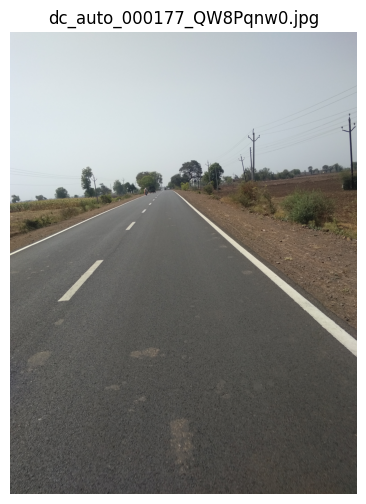


XML root: annotation
Annotation structure:
<annotation>
  <folder>dc</folder>
  <filename>dc_auto_000177_QW8Pqnw0.jpg</filename>
  <source>
    <database>Unknown</database>
    <annotation>Unknown</annotation>
    <image>Unknown</image>
  </source>
  <size>
    <width>3120</width>
    <height>4160</height>
    <depth />
  </size>
  <segmented>0</segmented>
  <object>
    <name>road_line</name>
    <truncated>0</truncated>
    <occluded>0</occluded>
    <difficult>0</difficult>
    <bndbox>
      <xmin>1280.56</xmin>
      <ymin>1505.68</ymin>
      <xmax>1303.48</xmax>
      <ymax>1518.08</ymax>
    </bndbox>
    <attributes>
      <attribute>
        <name>rotation</name>
        <value>0.0</value>
      </attribute>
    </attributes>
  </object>
  <object>
    <name>road_line</name>
    <truncated>0</truncated>
    <occluded>0</occluded>
    <difficult>0</difficult>
    <bndbox>
      <xmin>1244.49</xmin>
      <ymin>1538.82</ymin>
      <xmax>1274.55</xmax>
      <ymax>1558.03</yma

In [6]:

import os
import xml.etree.ElementTree as ET
from PIL import Image
import matplotlib.pyplot as plt

BASE = "/kaggle/input/datasets/dataclusterlabs/lane-detection-road-line-detection-image-dataset"

IMG_DIR = os.path.join(BASE, "road_line_images", "road_line_images")
ANN_DIR = os.path.join(BASE, "road_line_annotation", "road_line_annotation")

# Check number of images and annotations
images = sorted([
    f for f in os.listdir(IMG_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

annotations = sorted([
    f for f in os.listdir(ANN_DIR)
    if f.lower().endswith(".xml")
])

print("Total images:", len(images))
print("Total annotations:", len(annotations))
print("First image:", images[0] if images else "No images found")
print("First annotation:", annotations[0] if annotations else "No annotations found")

# Display one road image
if images:
    image_path = os.path.join(IMG_DIR, images[0])
    img = Image.open(image_path)

    plt.figure(figsize=(12, 6))
    plt.imshow(img)
    plt.axis("off")
    plt.title(images[0])
    plt.show()

# Inspect the XML annotation structure
if annotations:
    xml_path = os.path.join(ANN_DIR, annotations[0])
    root = ET.parse(xml_path).getroot()

    print("\nXML root:", root.tag)
    print("Annotation structure:")
    print(ET.tostring(root, encoding="unicode")[:4000])


Image: dc_auto_000177_QW8Pqnw0.jpg
Image size: (3120, 4160)
Road-line boxes: 8


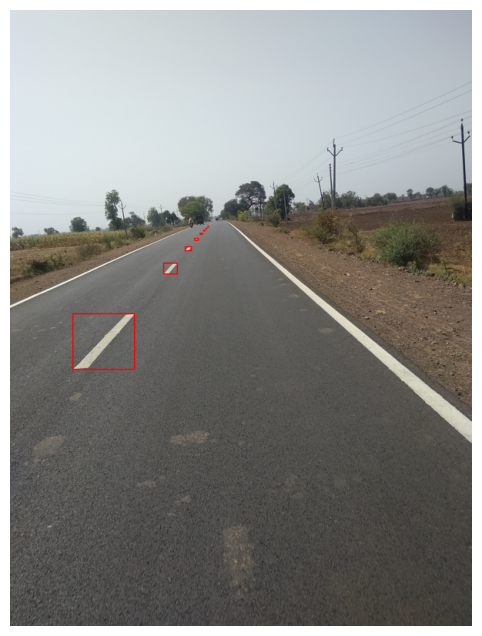

In [7]:

import os
import xml.etree.ElementTree as ET
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

BASE = "/kaggle/input/datasets/dataclusterlabs/lane-detection-road-line-detection-image-dataset"

IMG_DIR = os.path.join(BASE, "road_line_images", "road_line_images")
ANN_DIR = os.path.join(BASE, "road_line_annotation", "road_line_annotation")

image_name = sorted(os.listdir(IMG_DIR))[0]
image_path = os.path.join(IMG_DIR, image_name)
xml_path = os.path.join(
    ANN_DIR, os.path.splitext(image_name)[0] + ".xml"
)

image = Image.open(image_path).convert("RGB")
draw = ImageDraw.Draw(image)

root = ET.parse(xml_path).getroot()
count = 0

for obj in root.findall("object"):
    if obj.findtext("name") != "road_line":
        continue

    box = obj.find("bndbox")
    x1 = float(box.findtext("xmin"))
    y1 = float(box.findtext("ymin"))
    x2 = float(box.findtext("xmax"))
    y2 = float(box.findtext("ymax"))

    draw.rectangle((x1, y1, x2, y2), outline="red", width=8)
    count += 1

print("Image:", image_name)
print("Image size:", image.size)
print("Road-line boxes:", count)

# Resize only for display
image.thumbnail((800, 800))

plt.figure(figsize=(8, 8))
plt.imshow(image)
plt.axis("off")
plt.show()


Image: dc_auto_000177_QW8Pqnw0.jpg
Image size: (3120, 4160)
Road-line boxes: 8


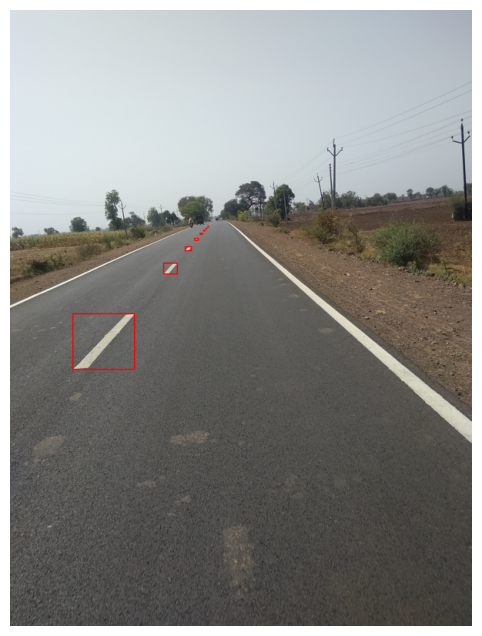

In [8]:

import os
import xml.etree.ElementTree as ET
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

BASE = "/kaggle/input/datasets/dataclusterlabs/lane-detection-road-line-detection-image-dataset"

IMG_DIR = os.path.join(BASE, "road_line_images", "road_line_images")
ANN_DIR = os.path.join(BASE, "road_line_annotation", "road_line_annotation")

image_name = sorted(os.listdir(IMG_DIR))[0]
image_path = os.path.join(IMG_DIR, image_name)
xml_path = os.path.join(
    ANN_DIR, os.path.splitext(image_name)[0] + ".xml"
)

image = Image.open(image_path).convert("RGB")
draw = ImageDraw.Draw(image)

root = ET.parse(xml_path).getroot()
count = 0

for obj in root.findall("object"):
    if obj.findtext("name") != "road_line":
        continue

    box = obj.find("bndbox")
    x1 = float(box.findtext("xmin"))
    y1 = float(box.findtext("ymin"))
    x2 = float(box.findtext("xmax"))
    y2 = float(box.findtext("ymax"))

    draw.rectangle((x1, y1, x2, y2), outline="red", width=8)
    count += 1

print("Image:", image_name)
print("Image size:", image.size)
print("Road-line boxes:", count)

# Resize only for display
image.thumbnail((800, 800))

plt.figure(figsize=(8, 8))
plt.imshow(image)
plt.axis("off")
plt.show()


In [9]:

import os
import xml.etree.ElementTree as ET
from collections import Counter

image_names = {
    os.path.splitext(f)[0]
    for f in os.listdir(IMG_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
}

xml_names = {
    os.path.splitext(f)[0]
    for f in os.listdir(ANN_DIR)
    if f.lower().endswith(".xml")
}

print("Images:", len(image_names))
print("XML files:", len(xml_names))
print("Images without XML:", sorted(image_names - xml_names))
print("XML without images:", sorted(xml_names - image_names))

box_counts = Counter()
invalid_xml = []

for name in sorted(image_names & xml_names):
    path = os.path.join(ANN_DIR, name + ".xml")

    try:
        root = ET.parse(path).getroot()
        box_counts[name] = len(root.findall("object"))
    except ET.ParseError:
        invalid_xml.append(name)

print("Valid annotations:", len(box_counts))
print("Invalid XML:", invalid_xml)
print("Total road-line objects:", sum(box_counts.values()))
print("Objects per image:", dict(box_counts))


Images: 50
XML files: 50
Images without XML: []
XML without images: []
Valid annotations: 50
Invalid XML: []
Total road-line objects: 172
Objects per image: {'dc_auto_000177_QW8Pqnw0': 8, 'dc_auto_000179_MdYqzu93': 8, 'dc_auto_000180_WHZmSiVx': 7, 'dc_auto_000869_fUaOFIP1': 2, 'dc_auto_000874_k9LK0YFB': 3, 'dc_auto_001865_tRgbasxm': 9, 'dc_auto_001867_G9fFComp': 7, 'dc_auto_001952_UOqgzYLe': 1, 'dc_auto_001955_v7vnp5E9': 1, 'dc_auto_002333_RHqEXByo': 5, 'dc_auto_004206_vwVEPMH1': 9, 'dc_auto_image_000156_modwC7i7z3': 3, 'dc_auto_image_000745_FtBnJ6AqNf': 3, 'dc_auto_image_001363_2aKIdjQxzD': 4, 'dc_auto_image_001827_yOJTWERkvJ': 12, 'dc_bus_image_000242_QlEjHhr8RD': 6, 'dc_bus_image_000435_aGBzNtn4XS': 4, 'dc_bus_image_000440_0CTdmruhb8': 2, 'dc_bus_image_000683_R6UGQdmkkn': 5, 'dc_bus_image_000705_yYmr0Hlq8E': 2, 'dc_bus_image_000820_1RaOmuHKDz': 4, 'dc_bus_image_000854_3fULAgVA6t': 2, 'dc_bus_image_001160_QpzvnDJ1bz': 2, 'dc_bus_image_001402_sZX91PgOrs': 2, 'dc_bus_image_001404_AwRA3

In [10]:

import os
import random
import xml.etree.ElementTree as ET

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

BASE = "/kaggle/input/datasets/dataclusterlabs/lane-detection-road-line-detection-image-dataset"

IMG_DIR = os.path.join(
    BASE, "road_line_images", "road_line_images"
)

ANN_DIR = os.path.join(
    BASE, "road_line_annotation", "road_line_annotation"
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch:", torch.__version__)
print("Device:", device)
print("Images:", len([
    f for f in os.listdir(IMG_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]))


PyTorch: 2.11.0+cpu
Device: cpu
Images: 50


In [11]:
import torch
import torch.nn as nn

class RoadLineCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 2)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = RoadLineCNN().to(device)

print(model)
print("Device:", device)

RoadLineCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)
Device: cpu


In [12]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 10

for epoch in range(epochs):

    # Training
    model.train()

    train_loss = 0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    # Validation
    model.eval()

    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    train_accuracy = 100 * train_correct / train_total
    val_accuracy = 100 * val_correct / val_total

    print(
        f"Epoch [{epoch + 1}/{epochs}] "
        f"Train Loss: {train_loss / train_total:.4f} "
        f"Train Accuracy: {train_accuracy:.2f}% "
        f"Val Loss: {val_loss / val_total:.4f} "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )

NameError: name 'train_loader' is not defined

In [ ]:
torch.save(
    model.state_dict(),
    "/kaggle/working/road_line_cnn.pth"
)

print("Model saved successfully!")

In [ ]:

import os
import random
import xml.etree.ElementTree as ET

import numpy as np
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

random.seed(42)

image_files = sorted([
    f for f in os.listdir(IMG_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

# Split original images first
random.shuffle(image_files)

split = int(0.8 * len(image_files))
train_files = image_files[:split]
val_files = image_files[split:]

print("Training images:", len(train_files))
print("Validation images:", len(val_files))

transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5)
    )
])

def get_boxes(image_name):
    xml_name = os.path.splitext(image_name)[0] + ".xml"
    xml_path = os.path.join(ANN_DIR, xml_name)

    root = ET.parse(xml_path).getroot()
    boxes = []

    for obj in root.findall("object"):
        if obj.findtext("name") != "road_line":
            continue

        box = obj.find("bndbox")

        boxes.append([
            float(box.findtext("xmin")),
            float(box.findtext("ymin")),
            float(box.findtext("xmax")),
            float(box.findtext("ymax"))
        ])

    return boxes

class RoadPatchDataset(Dataset):
    def __init__(self, filenames, patches_per_image=10):
        self.samples = []
        self.transform = transform

        for filename in filenames:
            image_path = os.path.join(IMG_DIR, filename)

            with Image.open(image_path) as im:
                image = im.convert("RGB")
                width, height = image.size

            boxes = get_boxes(filename)

            # Positive patches from annotated road-line boxes
            for x1, y1, x2, y2 in boxes:
                x1 = max(0, int(x1))
                y1 = max(0, int(y1))
                x2 = min(width, int(np.ceil(x2)))
                y2 = min(height, int(np.ceil(y2)))

                if x2 > x1 and y2 > y1:
                    self.samples.append(
                        (filename, (x1, y1, x2, y2), 1)
                    )

            # Negative patches away from annotated boxes
            for _ in range(patches_per_image):
                for attempt in range(100):
                    pw = random.randint(64, 256)
                    ph = random.randint(64, 256)

                    x1 = random.randint(0, max(0, width - pw))
                    y1 = random.randint(0, max(0, height - ph))
                    x2, y2 = x1 + pw, y1 + ph

                    overlaps = any(
                        x1 < bx2 and x2 > bx1
                        and y1 < by2 and y2 > by1
                        for bx1, by1, bx2, by2 in boxes
                    )

                    if not overlaps:
                        self.samples.append(
                            (filename, (x1, y1, x2, y2), 0)
                        )
                        break

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        filename, box, label = self.samples[idx]

        with Image.open(os.path.join(IMG_DIR, filename)) as im:
            image = im.convert("RGB")
            patch = image.crop(box)

        patch = self.transform(patch)
        return patch, label

train_dataset = RoadPatchDataset(train_files)
val_dataset = RoadPatchDataset(val_files)

train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True
)

val_loader = DataLoader(
    val_dataset, batch_size=32, shuffle=False
)

print("Training patches:", len(train_dataset))
print("Validation patches:", len(val_dataset))


In [ ]:
import torch
import torch.nn as nn

print("1. PyTorch imported")

print("2. Creating model...")

model = nn.Sequential(
    nn.Conv2d(3, 16, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2)
)

print("3. Model created successfully")
print(model)

print("4. CUDA available:", torch.cuda.is_available())

In [ ]:
print("Step A: Starting")

class RoadLineCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 2)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


print("Step B: Class defined")

model = RoadLineCNN()

print("Step C: Model created")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

print("Step D: Device assigned:", device)
print(model)

In [ ]:
import torch
import torch.nn as nn

print("1. Defining CNN...")

class RoadLineCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 2)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


print("2. Creating model...")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = RoadLineCNN().to(device)

print("3. Testing model...")

dummy_input = torch.randn(1, 3, 64, 64).to(device)

with torch.no_grad():
    output = model(dummy_input)

print("4. Output shape:", output.shape)
print("5. Device:", device)
print("CNN working successfully!")

In [ ]:
import torch
import torch.nn as nn

print("1. Defining CNN...")

class RoadLineCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 2)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


print("2. Creating model...")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = RoadLineCNN().to(device)

print("3. Testing model...")

dummy_input = torch.randn(1, 3, 64, 64).to(device)

with torch.no_grad():
    output = model(dummy_input)

print("4. Output shape:", output.shape)
print("5. Device:", device)
print("CNN working successfully!")

In [ ]:
import time
import torch

print("Checking DataLoader...", flush=True)

start = time.time()

images, labels = next(iter(train_loader))

print("Batch loaded!", flush=True)
print("Images shape:", images.shape, flush=True)
print("Labels shape:", labels.shape, flush=True)
print("Loading time:", round(time.time() - start, 2), "seconds", flush=True)

print("GPU:", torch.cuda.is_available(), flush=True)

In [ ]:
print("Starting one-batch training test...", flush=True)

model.train()

images, labels = next(iter(train_loader))
images = images.to(device)
labels = labels.to(device)

optimizer.zero_grad()

outputs = model(images)
loss = criterion(outputs, labels)

loss.backward()
optimizer.step()

print("One batch trained!", flush=True)
print("Loss:", loss.item(), flush=True)

In [ ]:
import time

print("Starting training test...", flush=True)
start = time.time()

model.train()

images, labels = next(iter(train_loader))
images = images.to(device)
labels = labels.to(device)

optimizer.zero_grad()

outputs = model(images)
loss = criterion(outputs, labels)

loss.backward()
optimizer.step()

print("One batch trained successfully!", flush=True)
print("Loss:", round(loss.item(), 4), flush=True)
print("Time:", round(time.time() - start, 2), "seconds", flush=True)

In [ ]:
import time
from tqdm.auto import tqdm

epochs = 10

for epoch in range(epochs):
    start = time.time()

    model.train()
    train_loss = 0
    train_correct = 0
    train_total = 0

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{epochs}"
    )

    for images, labels in progress:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        train_correct += (
            outputs.argmax(dim=1) == labels
        ).sum().item()
        train_total += labels.size(0)

        progress.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    model.eval()
    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            val_correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()
            val_total += labels.size(0)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Train Loss: {train_loss / train_total:.4f} | "
        f"Train Accuracy: "
        f"{100 * train_correct / train_total:.2f}% | "
        f"Val Loss: {val_loss / val_total:.4f} | "
        f"Val Accuracy: "
        f"{100 * val_correct / val_total:.2f}% | "
        f"Time: {time.time() - start:.1f}s",
        flush=True
    )

In [ ]:
torch.save(
    model.state_dict(),
    "/kaggle/working/road_line_cnn.pth"
)

print("CNN model saved successfully!")

In [ ]:
import matplotlib.pyplot as plt

model.eval()

image, label = val_dataset[0]

with torch.no_grad():
    output = model(image.unsqueeze(0).to(device))
    probabilities = torch.softmax(output, dim=1)
    prediction = output.argmax(dim=1).item()

# Convert normalized tensor back to displayable image
display_image = image.permute(1, 2, 0).cpu() * 0.5 + 0.5
display_image = display_image.clamp(0, 1)

class_names = ["Background", "Road Line"]

plt.figure(figsize=(5, 5))
plt.imshow(display_image)
plt.title(
    f"Actual: {class_names[label]}\n"
    f"Predicted: {class_names[prediction]}\n"
    f"Confidence: {probabilities[0, prediction].item() * 100:.2f}%"
)
plt.axis("off")
plt.show()

In [ ]:
import torch
import matplotlib.pyplot as plt
import random
import math

# Class names
class_names = ["Background", "Road Line"]

# Number of images to display
num_images = min(20, len(val_dataset))

# Select random validation patches
indices = random.sample(range(len(val_dataset)), num_images)

model.eval()

cols = 4
rows = math.ceil(num_images / cols)

plt.figure(figsize=(16, rows * 4))

correct = 0

for plot_idx, dataset_idx in enumerate(indices):
    image, actual_label = val_dataset[dataset_idx]

    # Predict
    with torch.no_grad():
        input_image = image.unsqueeze(0).to(device)
        outputs = model(input_image)
        probabilities = torch.softmax(outputs, dim=1)[0]

        predicted_label = outputs.argmax(dim=1).item()
        confidence = probabilities[predicted_label].item() * 100

    if predicted_label == actual_label:
        correct += 1

    # Convert normalized image for display
    display_image = image.permute(1, 2, 0).cpu() * 0.5 + 0.5
    display_image = display_image.clamp(0, 1)

    plt.subplot(rows, cols, plot_idx + 1)
    plt.imshow(display_image)

    result = "CORRECT" if predicted_label == actual_label else "WRONG"

    plt.title(
        f"Actual: {class_names[actual_label]}\n"
        f"Predicted: {class_names[predicted_label]}\n"
        f"Confidence: {confidence:.2f}% | {result}",
        fontsize=9
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

print(f"Correct predictions: {correct}/{num_images}")
print(f"Accuracy on displayed patches: {correct / num_images * 100:.2f}%")

from collections import Counter

model.eval()
actual_counts = Counter()
predicted_counts = Counter()

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        outputs = model(images)
        predictions = outputs.argmax(dim=1).cpu()

        actual_counts.update(labels.tolist())
        predicted_counts.update(predictions.tolist())

print("Actual labels:", actual_counts)
print("Predicted labels:", predicted_counts)

print("Class names: 0 = Background, 1 = Road Line")

In [ ]:
from collections import Counter

model.eval()
actual_counts = Counter()
predicted_counts = Counter()

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        outputs = model(images)
        predictions = outputs.argmax(dim=1).cpu()

        actual_counts.update(labels.tolist())
        predicted_counts.update(predictions.tolist())

print("Actual labels:", actual_counts)
print("Predicted labels:", predicted_counts)

print("Class names: 0 = Background, 1 = Road Line")

In [ ]:
from collections import Counter

train_labels = [label for _, label in train_dataset]
val_labels = [label for _, label in val_dataset]

print("Training patches:", Counter(train_labels))
print("Validation patches:", Counter(val_labels))

In [ ]:
criterion = nn.CrossEntropyLoss() 

class_counts = Counter(train_labels)

weights = torch.tensor([
    len(train_labels) / (2 * class_counts[0]),
    len(train_labels) / (2 * class_counts[1])
], dtype=torch.float32).to(device)

criterion = nn.CrossEntropyLoss(weight=weights)

print("Class weights:", weights)

In [ ]:
model.eval()

actual_counts = [0, 0]
predicted_counts = [0, 0]

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1).cpu()

        for label in labels:
            actual_counts[label.item()] += 1

        for pred in predictions:
            predicted_counts[pred.item()] += 1

print("Actual Background:", actual_counts[0])
print("Actual Road Line:", actual_counts[1])

print("Predicted Background:", predicted_counts[0])
print("Predicted Road Line:", predicted_counts[1])

In [ ]:
import torch
import matplotlib.pyplot as plt

class_names = ["Background", "Road Line"]

model.eval()
count = 0

plt.figure(figsize=(12, 8))

for i in range(len(val_dataset)):
    image, label = val_dataset[i]

    if label == 1:  # Only actual road-line patches
        with torch.no_grad():
            output = model(image.unsqueeze(0).to(device))
            probs = torch.softmax(output, dim=1)[0]

        pred = output.argmax(dim=1).item()

        plt.subplot(3, 4, count + 1)

        img = image.permute(1, 2, 0).cpu() * 0.5 + 0.5
        plt.imshow(img.clamp(0, 1))

        plt.title(
            f"Actual: Road Line\n"
            f"Predicted: {class_names[pred]}\n"
            f"Road probability: {probs[1].item():.3f}"
        )
        plt.axis("off")

        count += 1

        if count == 12:
            break

plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import random

class_names = ["Background", "Road Line"]

# Show 8 road-line patches and 8 background patches
positive = [i for i, (_, label) in enumerate(train_dataset) if label == 1]
negative = [i for i, (_, label) in enumerate(train_dataset) if label == 0]

selected = random.sample(positive, min(8, len(positive)))
selected += random.sample(negative, min(8, len(negative)))

plt.figure(figsize=(12, 8))

for i, idx in enumerate(selected):
    image, label = train_dataset[idx]

    image = image.permute(1, 2, 0) * 0.5 + 0.5

    plt.subplot(4, 4, i + 1)
    plt.imshow(image.clamp(0, 1))
    plt.title(class_names[label])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os
import xml.etree.ElementTree as ET

xml_files = [
    f for f in os.listdir(ANN_DIR)
    if f.lower().endswith(".xml")
]

print("Number of XML files:", len(xml_files))

xml_path = os.path.join(ANN_DIR, xml_files[0])
root = ET.parse(xml_path).getroot()

print("Image filename:", root.findtext("filename"))

for obj in root.findall("object"):
    name = obj.findtext("name")
    box = obj.find("bndbox")

    if box is not None:
        xmin = int(box.findtext("xmin"))
        ymin = int(box.findtext("ymin"))
        xmax = int(box.findtext("xmax"))
        ymax = int(box.findtext("ymax"))

        print(name, xmin, ymin, xmax, ymax)

In [ ]:
import os
import xml.etree.ElementTree as ET

xml_files = [
    f for f in os.listdir(ANN_DIR)
    if f.lower().endswith(".xml")
]

print("Number of XML files:", len(xml_files))

xml_path = os.path.join(ANN_DIR, xml_files[0])
root = ET.parse(xml_path).getroot()

print("Image filename:", root.findtext("filename"))

for obj in root.findall("object"):
    name = obj.findtext("name")
    box = obj.find("bndbox")

    if box is not None:
        xmin = int(float(box.findtext("xmin")))
        ymin = int(float(box.findtext("ymin")))
        xmax = int(float(box.findtext("xmax")))
        ymax = int(float(box.findtext("ymax")))

        print(name, xmin, ymin, xmax, ymax)

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt
import xml.etree.ElementTree as ET

xml_path = os.path.join(ANN_DIR, xml_files[0])
root = ET.parse(xml_path).getroot()

filename = root.findtext("filename").strip()
img_path = os.path.join(IMG_DIR, filename)

img = cv2.imread(img_path)

if img is None:
    print("Image not found:", img_path)
else:
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    for obj in root.findall("object"):
        box = obj.find("bndbox")

        if box is None:
            continue

        xmin = int(float(box.findtext("xmin")))
        ymin = int(float(box.findtext("ymin")))
        xmax = int(float(box.findtext("xmax")))
        ymax = int(float(box.findtext("ymax")))

        cv2.rectangle(
            img,
            (xmin, ymin),
            (xmax, ymax),
            (255, 0, 0),
            5
        )

    plt.figure(figsize=(10, 10))
    plt.imshow(img)
    plt.title("Road-line XML bounding boxes")
    plt.axis("off")
    plt.show()

In [ ]:

import os
import random
import xml.etree.ElementTree as ET

import numpy as np
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

random.seed(42)

image_files = sorted([
    f for f in os.listdir(IMG_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

random.shuffle(image_files)

split = int(0.8 * len(image_files))
train_files = image_files[:split]
val_files = image_files[split:]

transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5)
    )
])

def get_boxes(image_name):
    xml_name = os.path.splitext(image_name)[0] + ".xml"
    xml_path = os.path.join(ANN_DIR, xml_name)

    root = ET.parse(xml_path).getroot()
    boxes = []

    for obj in root.findall("object"):
        if obj.findtext("name") != "road_line":
            continue

        box = obj.find("bndbox")

        if box is not None:
            boxes.append((
                int(float(box.findtext("xmin"))),
                int(float(box.findtext("ymin"))),
                int(np.ceil(float(box.findtext("xmax")))),
                int(np.ceil(float(box.findtext("ymax"))))
            ))

    return boxes


class RoadPatchDataset(Dataset):
    def __init__(self, filenames, patches_per_image=10):
        self.samples = []

        for filename in filenames:
            image_path = os.path.join(IMG_DIR, filename)

            with Image.open(image_path) as im:
                width, height = im.size

            boxes = get_boxes(filename)

            # Positive patches: include the lane marking
            # and some surrounding road context.
            for bx1, by1, bx2, by2 in boxes:
                cx = (bx1 + bx2) // 2
                cy = (by1 + by2) // 2

                crop_w = min(192, width)
                crop_h = min(192, height)

                x1 = max(0, min(width - crop_w, cx - crop_w // 2))
                y1 = max(0, min(height - crop_h, cy - crop_h // 2))

                crop_box = (
                    x1, y1,
                    x1 + crop_w, y1 + crop_h
                )

                # Keep positive only if the annotation
                # actually intersects this crop.
                if (
                    x1 < bx2 and x1 + crop_w > bx1
                    and y1 < by2 and y1 + crop_h > by1
                ):
                    self.samples.append((filename, crop_box, 1))

            # Negative patches: avoid annotated boxes.
            crop_w = min(192, width)
            crop_h = min(192, height)

            for _ in range(patches_per_image):
                for attempt in range(200):
                    x1 = random.randint(0, width - crop_w)
                    y1 = random.randint(0, height - crop_h)

                    x2 = x1 + crop_w
                    y2 = y1 + crop_h

                    # Add a 16-pixel safety margin
                    # around each annotated box.
                    overlaps = any(
                        x1 < bx2 + 16 and x2 > bx1 - 16
                        and y1 < by2 + 16 and y2 > by1 - 16
                        for bx1, by1, bx2, by2 in boxes
                    )

                    if not overlaps:
                        self.samples.append((
                            filename,
                            (x1, y1, x2, y2),
                            0
                        ))
                        break

        print("Created patches:", len(self.samples))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        filename, box, label = self.samples[idx]

        with Image.open(os.path.join(IMG_DIR, filename)) as im:
            image = im.convert("RGB")
            patch = image.crop(box)

        return transform(patch), label


train_dataset = RoadPatchDataset(train_files)
val_dataset = RoadPatchDataset(val_files)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

from collections import Counter

train_labels = [label for _, _, label in train_dataset.samples]
val_labels = [label for _, _, label in val_dataset.samples]

print("Training images:", len(train_files))
print("Validation images:", len(val_files))
print("Training patches:", Counter(train_labels))
print("Validation patches:", Counter(val_labels))


In [ ]:
import torch
import torch.nn as nn
from collections import Counter

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = RoadLineCNN().to(device)

train_labels = [label for _, _, label in train_dataset.samples]
counts = Counter(train_labels)

weights = torch.tensor([
    len(train_labels) / (2 * counts[0]),
    len(train_labels) / (2 * counts[1])
], dtype=torch.float32).to(device)

criterion = nn.CrossEntropyLoss(weight=weights)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print("Device:", device)
print("Class weights:", weights)
print("Fresh model ready!")

In [ ]:
epochs = 10

for epoch in range(epochs):
    model.train()
    running_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = 100 * correct / total

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Loss: {train_loss:.4f} "
        f"Accuracy: {train_acc:.2f}%"
    )

In [ ]:
model.eval()
actual_counts = Counter()
predicted_counts = Counter()

with torch.no_grad():
    for images, labels in val_loader:
        outputs = model(images.to(device))
        predictions = outputs.argmax(dim=1).cpu()

        actual_counts.update(labels.tolist())
        predicted_counts.update(predictions.tolist())

print("Actual labels:", actual_counts)
print("Predicted labels:", predicted_counts)

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

model.eval()
y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1).cpu()

        y_true.extend(labels.tolist())
        y_pred.extend(predictions.tolist())

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Background", "Road Line"],
    zero_division=0
))

In [ ]:

import random
import matplotlib.pyplot as plt
import torch

class_names = ["Background", "Road Line"]

indices = random.sample(
    range(len(val_dataset)),
    min(16, len(val_dataset))
)

model.eval()
plt.figure(figsize=(14, 12))

for i, idx in enumerate(indices):
    image, actual = val_dataset[idx]

    with torch.no_grad():
        output = model(image.unsqueeze(0).to(device))
        probs = torch.softmax(output, dim=1)[0]
        pred = output.argmax(dim=1).item()

    display_image = image.permute(1, 2, 0).cpu() * 0.5 + 0.5

    plt.subplot(4, 4, i + 1)
    plt.imshow(display_image.clamp(0, 1))

    result = "CORRECT" if pred == actual else "WRONG"

    plt.title(
        f"Actual: {class_names[actual]}\n"
        f"Predicted: {class_names[pred]}\n"
        f"Road probability: {probs[1].item():.2f}\n"
        f"{result}",
        fontsize=9
    )
    plt.axis("off")

plt.tight_layout()
plt.show()
